![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluate — the Report

*Project 3 — AI Product: From Model to Product*

---

**This notebook is your report.** It is read on its own, by someone who has not seen notebooks 01 and 02: the question, the evidence, what you concluded and how far to trust it.

> **Done when:** the final version is evaluated once, its failures are analysed with examples, its cost is known, and the conclusions answer the question you framed in notebook 01.

---
## 0. Setup

In [1]:
import os
import sys
import logging
sys.path.append("..")          # so `src` is importable from inside notebooks/

os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

from src.functions import *

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

load_dotenv(ROOT / ".env")
print("Key found:", "OPENAI_API_KEY" in os.environ)

WINE, FOREST, NAVY, GREY = "#8c2045", "#4f9b63", "#2a5ca8", "#b8b6ae"

Key found: True


---
## 1. The question

The user, the decision, the metric and the baseline score, in a few sentences, as framed in notebook 01.

- **The user:** a hiker or nature enthusiast planning a trip to the mountains and national parks of the Balkans (Albania, Bosnia and Herzegovina, Bulgaria, Croatia, Kosovo, Montenegro, North Macedonia, Romania, and Serbia). They are at the planning stage, choosing where to go andpreparing the trip.
- **The product:** Mountain Goat, an agent that answers question from the Wikivoyage travel guides with their sources and recommends places based on where the user has been and how they rated the visit. It searches 11510 chunks of 619 Wikivoyage articles (`search_guides`) and read the user's travel log (`get_visited_places`). 
- **The decision it supports:** where to go and how to prepare, i.e. how to get there, how much it costs, where to sleep, etc.
- **The metric:**
    - **Retrieval:** whether the article that answers the user's question was found.
    - **Grounded accuracy:** correct answers that cite the expected articles so that the user can check it.
    - **Refusal on out-of-scope questions:** live conditions, places outside the specified region, booking, etc.


**The baseline** set in notebook 01: the same LLM with no guides and no tools answered **28%** of the 18 answerable questions correctly, cited nothing (**0% grounded**) and refused 3 of the 4 out-of-scope questions. Overall **36%** right.

---
## 2. The final evaluation

- **LLM track:** the whole evaluation set. Report separately: the retrieval hit rate (or the share of questions with the right tools), whether answers are correct and cite the right source, and whether the out-of-scope questions are refused.

In [2]:
# The final version, loaded as saved in notebook 02.

chunks = load_chunks()
eval_set = load_eval_set()
answerable = eval_set[eval_set['kind'] != 'out_of_scope']
embedding = load_embedder()
collection = open_collection()
print(f"Final settings: k = {TOP_K}, filter = {WHERE}, embedding model = {EMBEDDING_MODEL}, LLM = {LLM_MODEL}")

/Users/jkrstevska/Desktop/DSML/Week 9/project-3-ai-product/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7979.56it/s]


Final settings: k = 5, filter = None, embedding model = sentence-transformers/all-MiniLM-L6-v2, LLM = gpt-5.4-nano


In [3]:
# The 22 questions asked with an empty travel log, so here the answers depend only on the guides
EMPTY_LOG = ROOT / 'data' / 'processed' / 'eval_empty_log.csv'
EMPTY_LOG.unlink(missing_ok=True)

agent = make_agent(collection, embedding, EMPTY_LOG)

In [4]:
# The hit rate of the search tool on its own (as in notebook 02), check whether the expected article is among the top k chunks 
rate, missed = hit_rate(answerable, collection, embedding, k=TOP_K, where=WHERE)
print(f'Hit rate at k = {TOP_K}: {rate:.0%} ({round(rate * len(answerable))} of {len(answerable)})')
print(f'Missed: {missed}')

Hit rate at k = 5: 89% (16 of 18)
Missed: ['Can I drive to Theth in winter?', "I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?"]


In [6]:
# The agent answering the 22 evaluation questions
agent_answers = run_agent_eval(agent, eval_set)
review = eval_set.merge(agent_answers, on='question_id')
review[['question_id', 'kind', 'question', 'expected_answer', 'answer', 'tools']]

,question_id,kind,question,expected_answer,answer,tools
0,q01,fact,How much is the entry fee for Durmitor National Park?,€5 per day (checked 2025).,The entry fee for Durmitor National Park is **€5 per day (2025)**. [wv-2832],search_guides
1,q02,fact,How much does an adult ticket to Plitvice Lakes cost in July?,€40 for adults (1 June-30 September); €26.50 if entering after 4 PM in June-August.,"In July (which falls in 1 June–30 September), an adult ticket to Plitvice Lakes costs **€59.70**. [wv-6501]",search_guides
2,q03,practical,Can I drive to Theth in winter?,No: the road (SH21 from Koplik) is closed from November to April.,"Driving to Theth in winter is generally **not advisable** to do on your own, especially in bad weather, unless you have a **high-clearance vehicle** (4WD can be handy). [wv-167] The final **15–20 ...",search_guides
3,q04,fact,"How long does the hike from Theth to Valbona take, and how hard is it?","6-8 hours, via the Valbona Pass (1814 m); difficulty T2; marked red and white.",The hike from Theth to Valbona takes **6–8 hours**. [wv-9838] \nIts difficulty is listed as **T2** (moderate). [wv-9838] \nThe route goes from **Theth (742 m) → Valbona Pass (1814 m) → Rragam → ...,search_guides
4,q05,recommendation,Where can I try a via ferrata in Kosovo?,"In the Peja-Rugova Gorge (Rugova Mountains): 4 via ferrata trails, 300-1000 m long, reaching up to 300 m in height.",I don't know based on my guides.,search_guides
5,q06,practical,Do I need a permit or a ticket to hike in Retezat National Park?,"No permit or fee is needed; there are no bins, not even at huts, so carry your rubbish out.","You don’t need a permit or to pay a fee to access Retezat National Park. [wv-7445] \nIf you do something against the rules, you can get fined (for example, there’s no place to leave garbage, not ...",search_guides
6,q07,safety,Is it safe to hike off the marked trails around Valbona?,"Take care: unexploded ordnance from the Kosovo conflict is an issue off the beaten path, and the UK, Australia and Canada advise against travel to the Tropoja district, although law and order has ...",I don't know based on my guides.,search_guides
7,q08,fact,"What are Pelister's Eyes, and can I swim there?","Two mountain lakes: the Big lake at 2,218 m and the Small lake at 2,180 m; swimming is possible in the small one in summer; about a 5-hour walk from Dihovo, one way.","Pelister’s Eyes are two mountain lakes (the Big lake at 2,218 m and the Small lake at 2,180 m) inside Pelister National Park; they feed many rivers. [wv-6281] \nYes—it's possible to swim in the S...",search_guides
8,q09,safety,What should I watch out for when hiking in Piatra Craiului?,"Bears, especially in spring when they have cubs (back away slowly, do not run, make noise), and shepherd dogs guarding flocks (call the shepherd, carry a stick).","Watch out for bears: camping lower on the mountains can be risky (especially in spring when bears have cubs), and if you encounter bears with young you should back away slowly (don’t run) while ma...",search_guides
9,q10,fact,"What is the highest peak on Vitosha, and is there an easy way up?","Cherni Vrah, 2290 m; a lift from an outer neighbourhood of Sofia goes to just below the summit.",The highest summit on Vitosha is **Cherni Vrah (“The Black Peak”) at 2290 m**. [wv-10862] \nThere’s an **easy way up using the lift**: the guides note that there is a **cabin lift from Sofia** th...,search_guides


**Labelling.** Reading each answer next to the expected one and labelling it (same as in notebook 01):

| label | answerable questions | out-of-scope questions |
|---|---|---|
| `correct` | matches the expected answer | - |
| `partial` | right in part, with something missing or wrong | - |
| `wrong` | a different, outdated or made-up answer | answered instead of refusing |
| `refused` | said it doesn't know | said it doesn't know (the right outcome) |

In [7]:
LABELS = {   # question_id: (label, short reason)
    "q01": ("correct", ""),
    "q02": ("partial", "there are different prices depending on the season and type of entrantice ticket (one day vs. two days)"),
    "q03": ("wrong", "clearly states it's not allowed with dates specified"),
    "q04": ("correct", ""),
    "q05": ("refused", ""),
    "q06": ("correct", ""),
    "q07": ("refused", ""),
    "q08": ("correct", ""),
    "q09": ("correct", ""),
    "q10": ("correct", ""),
    "q11": ("correct", ""),
    "q12": ("correct", ""),
    "q13": ("correct", ""),
    "q14": ("partial", "it correctly answers for Krka, but refuses for Plitvice even though it clearly states it's not allowed"),
    "q15": ("correct", ""),
    "q16": ("correct", ""),
    "q17": ("refused", ""),
    "q18": ("correct", ""),
    "q19": ("refused", ""),
    "q20": ("refused", ""),
    "q21": ("refused", ""),
    "q22": ("refused", ""),
}

labels = pd.DataFrame([(q, label, reason) for q, (label, reason) in LABELS.items()],
                      columns=["question_id", "label", "reason"])
missing = labels.loc[labels["label"] == "", "question_id"].tolist()
if missing:
    print(f"Still to label: {missing}")

In [9]:
results = check_answers(review.merge(labels, on='question_id'), chunks)
results_answerable = results[results['kind'] != 'out_of_scope']
results_oos = results[results['kind'] == 'out_of_scope']

checks = ['right article retrieved', 'cites', 'cites only what it saw', 'cites the right article']
print(f'Answerable questions ({len(results_answerable)}):')
print(results_answerable[checks].mean().round(2).to_string())
print(f'\nOut-of-scope questions refused: {results_oos['refused'].sum()} of {len(results_oos)}')

Answerable questions (18):
right article retrieved    0.83
cites                      0.83
cites only what it saw     1.00
cites the right article    0.78

Out-of-scope questions refused: 4 of 4


In [33]:
# Test against the baseline

def scores(results, cites_source):
    """The headline scores of one system, from its labelled results."""
    answerable = results[results['kind'] != 'out_of_scope']
    oos = results[results['kind'] == 'out_of_scope']
    right = ((results["kind"] != "out_of_scope") & (results["label"] == "correct")) | \
            ((results["kind"] == "out_of_scope") & (results["label"] == "refused"))
    return pd.Series({
        "correct (answerable)": (answerable["label"] == "correct").mean(),
        "grounded: correct and citing the right article": ((answerable["label"] == "correct") & cites_source(answerable)).mean(),
        "out-of-scope refused": (oos["label"] == "refused").mean(),
        "right overall (all 22)": right.mean(),
    })

baseline = pd.read_csv(BASELINE_LABELS_FILE).fillna("")
comparison = pd.DataFrame({
    "LLM alone": scores(baseline, lambda r: pd.Series(False, index=r.index)),
    "Mountain Goat Agent": scores(results, lambda r: r["cites the right article"]),
})
comparison.style.format("{:.0%}")

,LLM alone,Mountain Goat Agent
correct (answerable),28%,67%
grounded: correct and citing the right article,0%,67%
out-of-scope refused,75%,100%
right overall (all 22),36%,73%


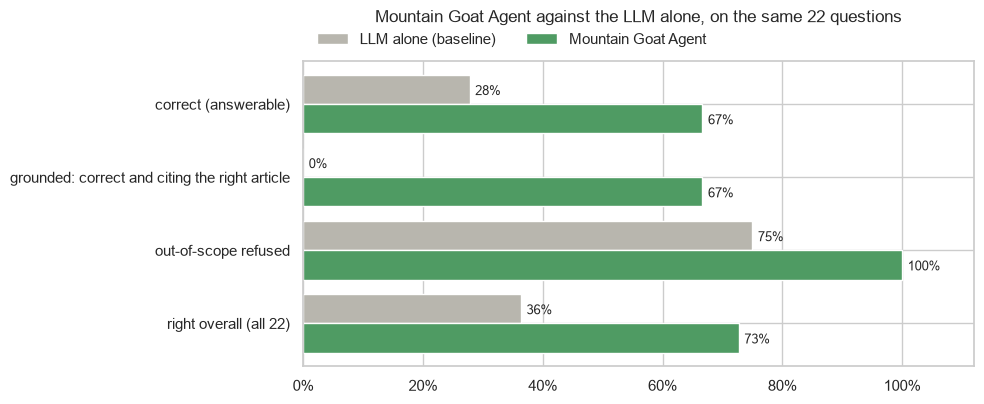

In [34]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(comparison))
ax.barh(y - 0.2, comparison["LLM alone"], height=0.4, color=GREY, label="LLM alone (baseline)")
ax.barh(y + 0.2, comparison["Mountain Goat Agent"], height=0.4, color=FOREST, label="Mountain Goat Agent")
for i, (b, t) in enumerate(zip(comparison["LLM alone"], comparison["Mountain Goat Agent"])):
    ax.annotate(f"{b:.0%}", (b, i - 0.2), textcoords="offset points", xytext=(4, -4), fontsize=9)
    ax.annotate(f"{t:.0%}", (t, i + 0.2), textcoords="offset points", xytext=(4, -4), fontsize=9)
ax.set_yticks(y, comparison.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Mountain Goat Agent against the LLM alone, on the same 22 questions", pad=28)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.tight_layout(); plt.show()

In [20]:
# Check by type of question
by_kind = results.groupby("kind").agg(
    questions=("question_id", "count"),
    correct=("label", lambda s: (s == "correct").mean()),
    refused=("label", lambda s: (s == "refused").mean()),
    cites_right_article=("cites the right article", "mean"),
)
by_kind.style.format({"correct": "{:.0%}", "refused": "{:.0%}", "cites_right_article": "{:.0%}"})

,questions,correct,refused,cites_right_article
kind,,,,
comparison,2,50%,0%,100%
fact,7,86%,0%,100%
out_of_scope,4,0%,100%,0%
practical,4,75%,0%,75%
recommendation,3,33%,67%,33%
safety,2,50%,50%,50%


Comparing the `Mountain Goat Agent` against the LLM alone, on the same 22 questions. On the 18 questions the guides can answer, Mountain Goat answered 67% correctly (12), more than twice the LLM alone (28%, 5), and 67% were correct and cited the right article, so the user can check them, against 0% for the LLM alone, which cites nothing. It refused all 4 out-of-scope questions (the LLM alone refused 3). Over the 22 questions, it handled 73% correctly (16), about twice as often as the LLM alone (36%, 8).

The `Mountain Goat Agent` works best on facts (6 of 7 correct) and practical questions (3 of 4), [safety: 1 of 2, comparison: 1 of 2]. Recommendations are the weakest, 1 of 3 correct and the other 2 refused (“I don’t know based on my guides”). Refusing is the safe failure since nothing is invented, but it leaves the user without help.

In [21]:
# Four test questions based on the information in the travel log, with the tools the agent should use. 

TOOL_TESTS = pd.DataFrame([
    ('t1', 'I loved Durmitor. Which national park should I visit next?', 'get_visited_places;search_guides'),
    ('t2', 'Which of the places I have visited did I rate the lowest?', 'get_visited_places'),
    ('t3', 'Recommend a hike in Albania that I have not done yet.', 'get_visited_places;search_guides'),
    ('t4', 'What is there to do in the place that I rated the highest?', 'get_visited_places;search_guides')
], columns=['question_id', 'question', 'expected_tools'])

In [22]:
# Load the demo log created in notebook 02
DEMO_LOG = ROOT / "data" / "processed" / "demo_visited.csv"
load_visited(DEMO_LOG)

,title,country,rating,visited_on,note
0,Durmitor National Park,Montenegro,5,,loved the lakes and the nature
1,Thethi,Albania,4,,beautiful but hard to reach
2,Plitvice Lakes National Park,Croatia,2,,too crowded


In [24]:
log_agent = make_agent(collection, embedding, DEMO_LOG)
tool_runs = TOOL_TESTS.merge(run_agent_eval(log_agent, TOOL_TESTS, path=TOOL_TESTS_FILE), on='question_id')
tool_runs['right_tools'] = [set(e.split(";")) <= set(t.split(";")) for e, t in zip(tool_runs["expected_tools"], tool_runs["tools"])]

print(f"Right tools: {tool_runs['right_tools'].sum()} of {len(tool_runs)} tool tests")
print(f"search_guides used on {results['tools'].str.contains('search_guides').sum()} of {len(results)} evaluation questions")

Right tools: 4 of 4 tool tests
search_guides used on 22 of 22 evaluation questions


In [26]:
tool_runs[["question_id", "question", "expected_tools", "tools", "right_tools", "answer"]]

,question_id,question,expected_tools,tools,right_tools,answer
0,t1,I loved Durmitor. Which national park should I visit next?,get_visited_places;search_guides,get_visited_places;search_guides,True,"Since you loved Durmitor’s lakes-and-nature vibe, **Skadar Lake National Park (Montenegro)** is a great next match: it’s described as the *largest lake on the Balkans* with *very rich cultural and..."
1,t2,Which of the places I have visited did I rate the lowest?,get_visited_places,get_visited_places,True,"You rated **Plitvice Lakes National Park (Croatia)** the lowest, at **2/5**."
2,t3,Recommend a hike in Albania that I have not done yet.,get_visited_places;search_guides,get_visited_places;search_guides;search_guides,True,I’d recommend hiking in the **Morava Mountains near Korçë**—the guides note you can “hike to the top of the beautiful mountain Morava” and that the area offers “fantastic hiking trails” with “stun...
3,t4,What is there to do in the place that I rated the highest?,get_visited_places;search_guides,get_visited_places;search_guides,True,"Durmitor National Park (your highest-rated place, 5/5) includes the Tara River canyon and the Durmitor mountain range (UNESCO World Heritage). [wv-2830] \nYou can focus on the lakes and natural s..."


The `Mountain Goat Agent` sucessfully used the right tools for all 4 questions. For t1 and t3 it didn't mention the places that have already been mentioned as visited. For t2 and t4 is successfully read the ratings correctly and gave accurate recommendations.

---
## 3. Where it goes wrong

- **LLM track:** every failure classified as a retrieval (or tool) failure or a generation failure, with examples.

Then: where should your product **not** be trusted?

In [27]:
failures = results[results["failure_source"] != ""]
print(failures["failure_source"].value_counts().to_string())
failures[["question_id", "kind", "question", "label", "failure_source", "expected_title", "retrieved_titles", "answer", "reason"]]

failure_source
generation    3
retrieval     3


,question_id,kind,question,label,failure_source,expected_title,retrieved_titles,answer,reason
1,q02,fact,How much does an adult ticket to Plitvice Lakes cost in July?,partial,generation,Plitvice Lakes National Park,[Plitvice Lakes National Park],"In July (which falls in 1 June–30 September), an adult ticket to Plitvice Lakes costs **€59.70**. [wv-6501]",there are different prices depending on the season and type of entrantice ticket (one day vs. two days)
2,q03,practical,Can I drive to Theth in winter?,wrong,retrieval,Thethi,"[Albania, Haskovo, Prokletije, Romania, Rožaje]","Driving to Theth in winter is generally **not advisable** to do on your own, especially in bad weather, unless you have a **high-clearance vehicle** (4WD can be handy). [wv-167] The final **15–20 ...",clearly states it's not allowed with dates specified
4,q05,recommendation,Where can I try a via ferrata in Kosovo?,refused,retrieval,Rugova Mountains,"[Ferizaj, Podujeva, Pristina, Vushtrri]",I don't know based on my guides.,
6,q07,safety,Is it safe to hike off the marked trails around Valbona?,refused,generation,Valbona Valley National Park,[Valbona Valley National Park],I don't know based on my guides.,
13,q14,comparison,Can I swim at Plitvice Lakes or at Krka National Park?,partial,generation,Plitvice Lakes National Park; Krka National Park,"[Krka National Park, Plitvice Lakes National Park]","I don’t know based on my guides whether swimming is allowed at Plitvice Lakes National Park. [wv-6497] \nAt Krka National Park, swimming is only allowed in the designated swimming area at the low...","it correctly answers for Krka, but refuses for Plitvice even though it clearly states it's not allowed"
16,q17,recommendation,I'd like a long multi-day trek through the Accursed Mountains. What do you suggest?,refused,retrieval,Prokletije,"[Breb, Herceg Novi, Targovishte, Žabljak]",I don't know based on my guides.,


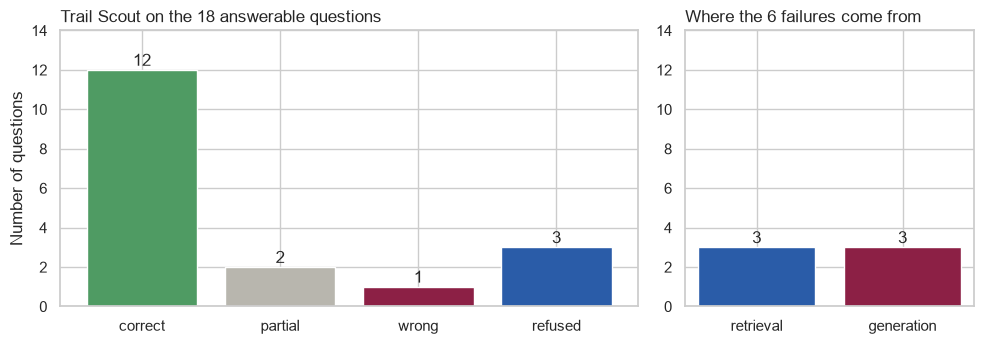

In [28]:
counts = results[results["kind"] != "out_of_scope"]["label"].value_counts().reindex(["correct", "partial", "wrong", "refused"], fill_value=0)
sources = failures["failure_source"].value_counts().reindex(["retrieval", "generation"], fill_value=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [4, 2]})
ax1.bar(counts.index, counts.values, color=[FOREST, GREY, WINE, NAVY])
ax1.set_title(f"Mountain Goat on the {len(results_answerable)} answerable questions", loc="left")
ax1.set_ylabel("Number of questions")
ax2.bar(sources.index, sources.values, color=[NAVY, WINE])
ax2.set_title(f"Where the {len(failures)} failures come from", loc="left")
for ax, values in [(ax1, counts.values), (ax2, sources.values)]:
    for i, v in enumerate(values):
        ax.annotate(str(v), (i, v), textcoords="offset points", xytext=(0, 3), ha="center")
    ax.set_ylim(0, max(max(counts.values), max(sources.values, default=0)) + 2)
plt.tight_layout(); plt.show()

Out of the 22 questions 6 fail, 3 in retrieval and 3 in generation.

Retrieval: For q05 and q17, the search returned other places, and the agent correctly refused rather than guessing. q05 was found in notebook 02 with the question as typed, but here the agent wrote its own search query, and it retrieved some towns instead of the Rugova Mountains. q03 is the *most serious* failure, the Thethi article was not retrieved, and instead of refusing, the agent gave general driving advice from the Prokletije article and missed the key fact that the road is closed from November to April. A plausible answer missing a safety-critical fact is a type mistake the agent should avoid.

Generation: For q02, the agent gave €59.70 for an adult ticket in July, a price from the wrong ticket type (the one-day ticket is €40): the Plitvice fee section lists many prices, and the model picked the wrong one. For q07 and q14, the right article was retrieved, but not the section with the answer, so the agent refused. This is a safe outcome, though the guides contain the answer.

Where `Mountain Goat Agent` should not be trusted based on what's been seen so far: 
- questions with several possible answers in one section eg: ticket prices by type and/or season 
- questions using a name that is not present in the guides
- practical questions where general country information can outrank the specific place eg: roads, driving
- anything that requires live information eg: weather, crowds, etc. 
At the current state, it is most reliable for specific facts about a named park.

---
## 4. Cost and speed

- **LLM track:** tokens, cost and time per question, and the total for the evaluation. What would 1,000 questions a day cost per month?

In [30]:
per_question = agent_answers[["input_tokens", "output_tokens", "cost_usd", "seconds"]]
summary = pd.DataFrame({"mean per question": per_question.mean().round(2), "max": per_question.max().round(2), f"total ({len(agent_answers)} questions)": per_question.sum().round(2)})
summary.loc["seconds", f"total ({len(agent_answers)} questions)"] = per_question["seconds"].sum()
display(summary.round(5))

,mean per question,max,total (22 questions)
input_tokens,1768.41,5423.00,38905.00
output_tokens,91.36,213.00,2010.00
cost_usd,0.00,0.00,0.01
seconds,2.40,4.49,52.70


In [31]:
cost_per_question = agent_answers["cost_usd"].mean()
baseline_cost = baseline["cost_usd"].mean() if "cost_usd" in baseline else float("nan")
print(f"Cost per question: ${cost_per_question:.5f} (the LLM alone: ${baseline_cost:.5f})")
print(f"Time per question: {per_question['seconds'].mean():.1f} sec on average, {per_question['seconds'].max():.1f} sec at most")
print(f"1,000 questions a day for 30 days: ${cost_per_question * 1000 * 30:.2f} a month")

Cost per question: $0.00047 (the LLM alone: $0.00010)
Time per question: 2.4 sec on average, 4.5 sec at most
1,000 questions a day for 30 days: $14.04 a month


---
## 5. The saved model or pipeline

Reload what you saved in notebook 02 and use it on a new example, exactly as the app does.

In [32]:
# Load the embedding model, open the saved index, build the agent, ask a new question
app_embedding = load_embedder()
app_collection = open_collection()
app_agent = make_agent(app_collection, app_embedding)

show_trace(run_agent(app_agent, "Where can I see waterfalls in North Macedonia?", step="app check"))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7925.69it/s]


  -> search_guides({'query': 'waterfalls in North Macedonia'})
  (1,520 input and 221 output tokens)

Answer: You can see waterfalls in North Macedonia at **Novo Selo** (home to Macedonia’s two best-known waterfalls, including its tallest) [wv-2912], **Belovište** (Belovište springs and waterfalls—roaring waters further into the mountains; the base area is accessible by paved road but the climb can be challenging) [wv-9729], and in **Mavrovo National Park** including **Korab Falls** (on the upper Dlaboka River; water flow is greatest in spring) and **Duf Falls** near Rostuša (reachable via an easy ~half-hour hike by the river canyon; falls flow year-round) [wv-5037] [wv-5039]. There are also **Gabrovo Waterfalls** above the village of Gabrovo on Belasica Mountain (a group of three small waterfalls, with a trail from the parking lot to the biggest one) [wv-9411].


---
## 6. Conclusions and limitations

Would you ship it, to whom, and with what warning? What data, products or questions does it hold for? What would you do next?

- **Would you ship it, to whom, and with what warning?** Yes, the `Mountain Goat Agent` can be leveraged as a research aid for hikers and nature enthusiasts planning a trip to the mountains or national parks in the Balkan Region. On the evaluation set it handled 73% of the questions correctly, against 36% for the LLM alone, 67% of its answers were correct and cited the right article, so the user can check them. It successfully refused every question the guides cannot answer. The warning: use it to discover and prepare, not for safety decisions or route planning. In the evaluation it gave confident driving advice for Theth but missed that the road is closed from November to April, and it gave the wrong ticket price for Plitvice. Always open and double check the cited source.
- **What it holds for:** the Wikivoyage guides for Albania, Bosnia and Herzegovina, Bulgaria, Croatia, Kosovo, Montenegro, North Macedonia, Romania and Serbia, as downloaded on 6 November 2026, questions in English, specific facts about a named park or town, where it is most reliable.
- **What it does not hold for:** live conditions (weather, snow, trails today), exact prices (sections with several ticket types confuse it, and 41% of listings were last checked in 2020 or earlier), places outside the countries mentioned, questions using a name the guides do not use, general practical questions (driving, roads), where the long country articles can outrank the specific place.
- **What would change the recommendation:** a larger evaluation showing the safety-related failures (like Theth) are rare or a fix/solution for them.
- **What I would do next:** add alternative and English place names to the chunks, improve retrieval at section level, so that “Stay safe” or “Fees and permits” is found when the question asks about safety or prices, build a larger evaluation set, with more recommendation questions, and expand the scope to more of Europe. Then a user who has visited popular places like the Alps could discover similar but less crowded destinations in countries they have not visited yet.